# 09 · Capacity sweep: does lower capacity generalise better to unseen attacks?

Three tuned models cannot show whether *simplicity* helps. This notebook varies one capacity parameter per family, keeping the other hyperparameters at the primary-seed tuned values, and measures for each setting:

- **novelty CV AUC** (leave-attack-types-out on `KDDTrain+`, training data only);
- **test ROC-AUC** of unseen attacks vs normals and of seen attacks vs normals (`KDDTest+`);
- a complexity measure (leaves, or coefficient norm for LR).

The test-set numbers here are **descriptive only**: nothing in this notebook is used to choose a model or a hyperparameter.

**Outputs:** `results/tables/capacity_sweep.*`, `results/figures/capacity/*.png`.

In [1]:
import sys, json, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src.config import set_all_seeds
from src import controlled_framework as cf

rng = set_all_seeds(cf.SEED)
sns.set_theme(style="whitegrid", context="notebook")
print(f"primary seed={cf.SEED} | seeds={cf.SEEDS} | trials={cf.N_TRIALS} | novelty CV folds={cf.N_SPLITS} | "
      f"threshold={cf.THRESHOLD} | FPR budgets={cf.FPR_BUDGETS} | class_weight={cf.CLASS_WEIGHT}")

primary seed=42 | seeds=[42, 1, 2, 3, 4] | trials=25 | novelty CV folds=5 | threshold=0.5 | FPR budgets=[0.01, 0.02, 0.05] | class_weight=None


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

data = cf.load_dataset()
best = {k: json.loads((cf.TUNING_DIR / f"{k}_trials.json").read_text())["best_params"]
        for k in ["logistic_regression", "decision_tree", "random_forest", "xgboost"]}

def leaves(clf):
    if hasattr(clf, "estimators_"):
        return int(sum(e.get_n_leaves() for e in clf.estimators_))
    if hasattr(clf, "get_n_leaves"):
        return int(clf.get_n_leaves())
    if hasattr(clf, "get_booster"):
        t = clf.get_booster().trees_to_dataframe(); return int((t["Feature"] == "Leaf").sum())
    return float(np.linalg.norm(clf.coef_))

SWEEPS = {
    "Logistic Regression": (LogisticRegression, "C", [1e-3, 1e-2, 1e-1, 1, 10, 100], 5),
    "Decision Tree": (DecisionTreeClassifier, "max_depth", [1, 2, 3, 4, 6, 8, 10, 15, 20, None], 5),
    "Random Forest": (RandomForestClassifier, "max_depth", [2, 4, 6, 8, 12, 16, 24, None], 1),
    "XGBoost": (XGBClassifier, "max_depth", [1, 2, 3, 4, 6, 8, 10], 1),
}
print({k: v[1] for k, v in SWEEPS.items()})

{'Logistic Regression': 'C', 'Decision Tree': 'max_depth', 'Random Forest': 'max_depth', 'XGBoost': 'max_depth'}


In [3]:
rows = []
for name, (Est, param, values, jobs) in SWEEPS.items():
    base = dict(best[cf.file_key(name)])
    for v in values:
        params = {**base, param: v}
        cv_auc, fold_aucs, _ = cf.novelty_cv(lambda p, E=Est: E(**p), params, data, cf.SEED, fold_jobs=jobs)
        pipe = cf.make_pipeline(lambda p, E=Est: E(**p), params, data.X_train).fit(data.X_train, data.y_train)
        prob = pipe.predict_proba(data.X_test)[:, 1]
        unseen = data.test_df["label"].isin(data.unseen_attacks).to_numpy()
        tf = cf.threshold_free(data.y_test.to_numpy(), prob, unseen)
        rows.append({"model": name, "param": param, "value": "None" if v is None else v,
                     "complexity": leaves(pipe.named_steps["clf"]), "novelty_cv_auc": cv_auc,
                     "test_auc_unseen_vs_normal": tf["roc_auc_unseen_vs_normal"],
                     "test_auc_seen_vs_normal": tf["roc_auc_seen_vs_normal"], "tuned_value": str(base.get(param))})
        print(f"{name:20s} {param}={v!s:6s} CV AUC {cv_auc:.4f} | test unseen AUC {tf['roc_auc_unseen_vs_normal']:.4f} | seen AUC {tf['roc_auc_seen_vs_normal']:.4f}")
sweep = pd.DataFrame(rows)
cf.save_table(sweep, "capacity_sweep")

Logistic Regression  C=0.001  CV AUC 0.9036 | test unseen AUC 0.8812 | seen AUC 0.9102
Logistic Regression  C=0.01   CV AUC 0.9019 | test unseen AUC 0.8718 | seen AUC 0.8784
Logistic Regression  C=0.1    CV AUC 0.8877 | test unseen AUC 0.8000 | seen AUC 0.8521
Logistic Regression  C=1      CV AUC 0.8839 | test unseen AUC 0.7473 | seen AUC 0.8131
Logistic Regression  C=10     CV AUC 0.8799 | test unseen AUC 0.7248 | seen AUC 0.8069
Logistic Regression  C=100    CV AUC 0.8799 | test unseen AUC 0.7101 | seen AUC 0.8084
Decision Tree        max_depth=1      CV AUC 0.7678 | test unseen AUC 0.7907 | seen AUC 0.8303
Decision Tree        max_depth=2      CV AUC 0.8070 | test unseen AUC 0.7873 | seen AUC 0.8755
Decision Tree        max_depth=3      CV AUC 0.8618 | test unseen AUC 0.7868 | seen AUC 0.9239
Decision Tree        max_depth=4      CV AUC 0.9163 | test unseen AUC 0.7603 | seen AUC 0.9275
Decision Tree        max_depth=6      CV AUC 0.8940 | test unseen AUC 0.8305 | seen AUC 0.9331
Dec

{'csv': PosixPath('/home/dhruvv_w/Documents/instrusion_detection/results/tables/capacity_sweep.csv'),
 'md': PosixPath('/home/dhruvv_w/Documents/instrusion_detection/results/tables/capacity_sweep.md')}

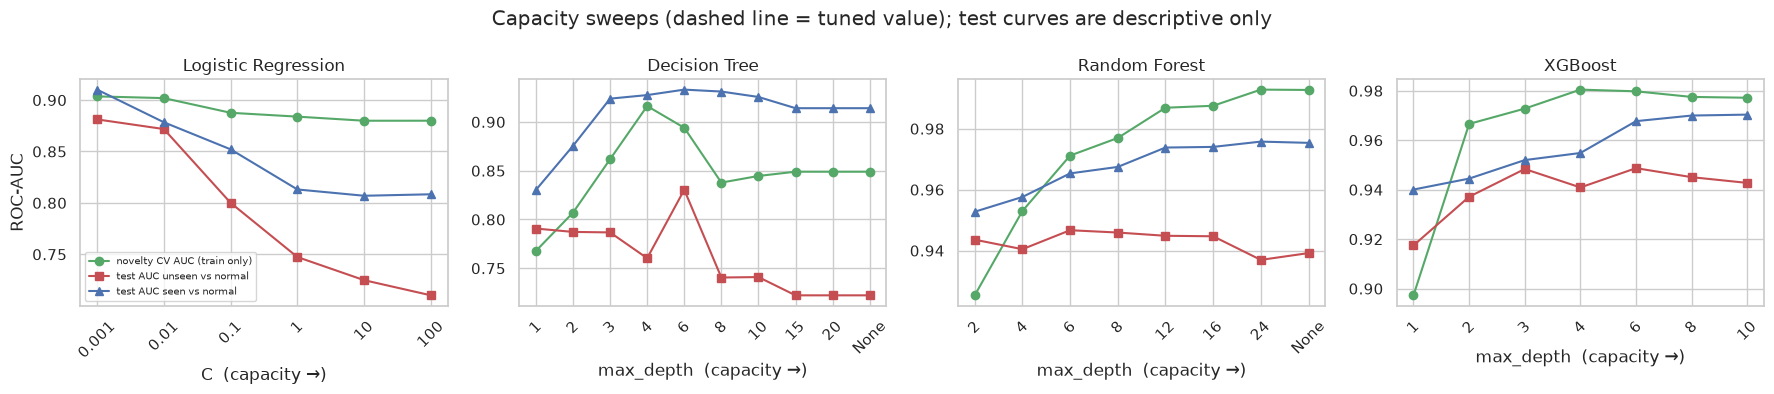

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=False)
for ax, (name, g) in zip(axes, sweep.groupby("model", sort=False)):
    x = np.arange(len(g))
    ax.plot(x, g.novelty_cv_auc, "o-", label="novelty CV AUC (train only)", color="#55A868")
    ax.plot(x, g.test_auc_unseen_vs_normal, "s-", label="test AUC unseen vs normal", color="#C44E52")
    ax.plot(x, g.test_auc_seen_vs_normal, "^-", label="test AUC seen vs normal", color="#4C72B0")
    tuned = g.tuned_value.iloc[0]
    if tuned in list(g.value.astype(str)):
        ax.axvline(list(g.value.astype(str)).index(tuned), color="grey", ls="--", lw=.8)
    ax.set_xticks(x, g.value.astype(str), rotation=45); ax.set_xlabel(g.param.iloc[0] + "  (capacity →)"); ax.set_title(name)
axes[0].set_ylabel("ROC-AUC"); axes[0].legend(fontsize=7)
fig.suptitle("Capacity sweeps (dashed line = tuned value); test curves are descriptive only"); fig.tight_layout()
cf.save_figure(fig, "capacity", "capacity_sweep"); plt.show()

In [5]:
# Within each family: does the capacity value that is best on the training-only novelty CV also do well on test?
summ = []
for name, g in sweep.groupby("model", sort=False):
    a = g.loc[g.novelty_cv_auc.idxmax()]; b = g.loc[g.test_auc_unseen_vs_normal.idxmax()]
    summ.append({"model": name, "param": a.param, "best_by_novelty_cv": a.value, "its_test_unseen_auc": a.test_auc_unseen_vs_normal,
                 "best_by_test_unseen_auc": b.value, "max_test_unseen_auc": b.test_auc_unseen_vs_normal,
                 "spearman_cv_vs_test": g[["novelty_cv_auc", "test_auc_unseen_vs_normal"]].corr("spearman").iloc[0, 1]})
summ = pd.DataFrame(summ)
cf.save_table(summ, "capacity_sweep_summary")
summ

,model,param,best_by_novelty_cv,its_test_unseen_auc,best_by_test_unseen_auc,max_test_unseen_auc,spearman_cv_vs_test
0,Logistic Regression,C,0.001,0.881220,0.001,0.881220,0.942857
1,Decision Tree,max_depth,4.000,0.760320,6.000,0.830472,-0.043478
2,Random Forest,max_depth,24.000,0.936960,6.000,0.946691,-0.428571
3,XGBoost,max_depth,4.000,0.940907,6.000,0.948706,0.535714


**How to read this.** If simpler models generalised better, unseen-vs-normal AUC would fall as capacity grows within each family. The Spearman column shows whether the training-only novelty CV ranks capacity settings the way the test set does, i.e. whether it is a usable proxy for tuning.